# 07 — Tuning the sequence models: is the Transformer's loss to the CNN real?

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**Why this notebook.** In notebook 06 the Transformer (and the GRU) detect worse than the 1-D CNN. That comparison had a small training budget (at most 12 epochs, 2 seeds, no tuning of depth, width or patch size), so "the Transformer loses" is only a statement about *that* budget. Here the result is stress-tested by changing **one lever at a time**:

| lever | variants | question |
|---|---|---|
| **data** | fresh injections at every epoch (new morphology, SNR, parameters, phase) for the CNN, the Transformer and the hybrid | is the Transformer data-limited? (the same lever is given to the CNN: the comparison stays fair) |
| **optimisation** | peak learning rate 3·10⁻³ instead of 10⁻³; the 25-epoch run of notebook 06 | is it an optimisation problem? |
| **resolution** | patch of 8 samples (128 tokens) instead of 16 (64 tokens) | does the patch embedding resolve the bursts? |
| **inductive bias** | a convolutional stem (the backbone of the CNN, 8× down-sampling) followed by two Transformer blocks on 128 tokens | is the weak point the *first* layer, not the attention? |

**What it does not do**: no new data, no new physics — same chunks, same split, same test injections (seed 777, verified identical to notebooks 05–06), same thresholds on the validation noise; the multiclass task of notebook 06 is not repeated. Conclusions are for the budget used here (≤ 20 epochs, one or two seeds), still small compared to what a large-scale study would use.

The models are trained by `seq_models.py` (resumable; the training was run in parallel processes) and cached in `cache/models/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()

CH, data, S1, DS = sm.load_data()
TEST = sm.make_test_sets(data, S1)
RAW = pickle.load(open(os.path.join(g.CACHE, "stats06.pkl"), "rb"))       # logits of the notebook-05/06 models on the same sets
SNRS = sm.SNRS; MORPHS = g.MORPHS
print({sp: len(d[0]) for sp, d in data.items()}, "test sets:", len(TEST))

{'train': 16224, 'val': 8112, 'test': 8112} test sets: 33


## 1. Diagnosis: the Transformers of notebook 06 *under-fit*

Training and validation loss at the end of training (best validation epoch) for the models of notebooks 05–06. A model that over-fits has a training loss far below the validation loss (the CNN); a model that under-fits has both high and close.

In [2]:
def hist_row(label, path):
    h = json.load(open(os.path.join(sm.MODELS, path)))
    k = int(np.argmin(h["val_loss"])); return dict(model=label, epochs=len(h["loss"]), train_loss_at_best=h["loss"][k], val_loss_best=h["val_loss"][k])
diag = pd.DataFrame([hist_row("CNN (nb05, seed 0)", "cnn_mix_s0_hist.json"), hist_row("CNN (nb05, seed 1)", "cnn_mix_s1_hist.json"),
                     hist_row("Transformer (nb06, seed 0, 25 ep)", "tf_bin_s0_hist.json"), hist_row("Transformer (nb06, seed 1, 12 ep)", "tf_bin_s1_hist.json"),
                     hist_row("Transformer + MAE (nb06)", "tfp_bin_s0_hist.json"), hist_row("GRU (nb06)", "gru_bin_s0_hist.json")])
diag["gap (val - train)"] = diag.val_loss_best - diag.train_loss_at_best
diag.round(3)

,model,epochs,train_loss_at_best,val_loss_best,gap (val - train)
0,"CNN (nb05, seed 0)",14,0.142,0.165,0.022
1,"CNN (nb05, seed 1)",12,0.139,0.151,0.012
2,"Transformer (nb06, seed 0, 25 ep)",25,0.282,0.312,0.030
3,"Transformer (nb06, seed 1, 12 ep)",12,0.301,0.310,0.009
4,Transformer + MAE (nb06),12,0.290,0.303,0.013
5,GRU (nb06),12,0.261,0.292,0.031


At the best-validation epoch every model has a small train–validation gap (0.01–0.03: early stopping picks that epoch), but the **level** of the loss is very different: 0.15–0.17 for the CNN, 0.29–0.31 for the Transformers and 0.29 for the GRU. The sequence models of notebook 06 are limited by *what they can fit*, not by over-fitting (training loss ≈ validation loss ≈ 0.3).
The new runs add the CNN side of the picture (section 2): with the same optimiser and the *static* data the CNN over-fits (training loss 0.07–0.09 against validation 0.17–0.19 at the best epoch, and a validation loss that rises again after epoch 15), and fresh injections cure it (validation 0.117). So the two families fail in opposite ways: the CNN is **data-limited**, the patch Transformer is **capacity/bias-limited**. Giving the Transformer more data should not help it much, while giving it to the CNN should — which is what the experiment tests.

## 2. Training of the variants

All variants share the optimiser (AdamW, weight decay 10⁻⁴, 2-epoch warm-up then cosine decay), batch 128, the best-validation epoch is restored, patience 6. *Static* = the 32 448 windows of notebooks 05–06; *fresh* = the same noise windows with newly drawn injections at every epoch (≈ 1.3 s per epoch to generate). Budget: 12 epochs for the sequence models (the budget of notebook 06; its 25-epoch run is the reference for "longer"), 20 for the CNN (17 min on a laptop on battery power; the Transformer variants 23–81 min).

In [3]:
MD, HIST = {}, {}
t0_ = time.time()
for name, (spec, fresh, epochs, lr, seeds) in sm.VARIANTS.items():
    for s in seeds:
        m, h = sm.train_variant(name, DS, S1["train"], seed=s, verbose=False)
        MD[(name, s)], HIST[(name, s)] = m, h
print("all variants trained / loaded: %.0f s" % (time.time() - t0_))
rows = []
for (name, s), h in HIST.items():
    k = int(np.argmin(h["val_loss"])); spec, fresh, epochs, lr, _ = sm.VARIANTS[name]
    rows.append(dict(variant=name, seed=s, params=MD[(name, s)].count_params(), fresh_injections=fresh, peak_lr=lr, epochs_run=len(h["loss"]), best_epoch=k + 1,
                     train_loss=h["loss"][k], val_loss=h["val_loss"][k], minutes=sum(h["seconds"]) / 60))
train_tab = pd.DataFrame(rows); train_tab.round(3)

all variants trained / loaded: 1 s


,variant,seed,params,fresh_injections,peak_lr,epochs_run,best_epoch,train_loss,val_loss,minutes
0,cnn_static,0,17761,False,0.002,20,15,0.091,0.187,17.368
1,cnn_static,1,17761,False,0.002,20,17,0.065,0.174,16.842
2,cnn_fresh,0,17761,True,0.002,20,17,0.087,0.118,17.161
3,cnn_fresh,1,17761,True,0.002,20,18,0.084,0.117,17.699
4,tf16_static_lr3,0,114049,False,0.003,12,12,0.295,0.316,22.654
5,tf16_fresh,0,114049,True,0.001,12,12,0.303,0.301,22.800
6,tf8_static,0,117633,False,0.001,12,11,0.306,0.311,80.852
7,hyb_static,0,99233,False,0.001,12,7,0.236,0.267,71.246
8,hyb_fresh,0,99233,True,0.001,12,11,0.229,0.248,71.416


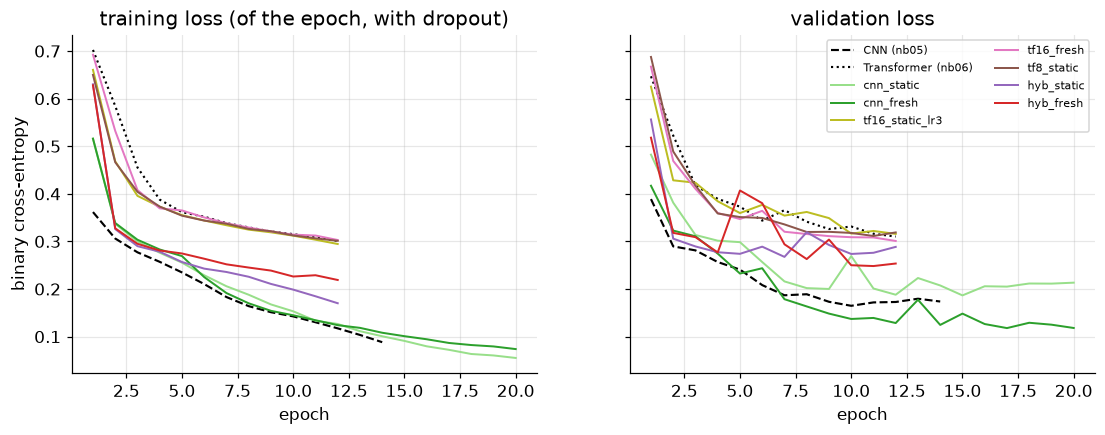

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
base = {"CNN (nb05)": "cnn_mix_s0_hist.json", "Transformer (nb06)": "tf_bin_s1_hist.json"}
colors = {"cnn_static": "#98df8a", "cnn_fresh": g.COLORS["ml"], "tf16_static_lr3": "#bcbd22", "tf16_fresh": "#e377c2", "tf8_static": "#8c564b", "hyb_static": g.COLORS["purple"], "hyb_fresh": g.COLORS["bayes"]}
for a, key, title in ((ax[0], "loss", "training loss (of the epoch, with dropout)"), (ax[1], "val_loss", "validation loss")):
    for lab, f in base.items():
        h = json.load(open(os.path.join(sm.MODELS, f))); a.plot(np.arange(1, len(h[key]) + 1), h[key], color="k", ls="--" if "CNN" in lab else ":", lw=1.4, label=lab)
    for (name, s), h in HIST.items():
        if s == 0: a.plot(np.arange(1, len(h[key]) + 1), h[key], color=colors[name], lw=1.3, label=name)
    a.set_xlabel("epoch"); a.set_title(title)
ax[0].set_ylabel("binary cross-entropy"); ax[1].legend(fontsize=7.5, ncol=2)
g.savefig(fig, "fig07_training_curves"); plt.show()

## 3. Detection performance on the same injections

Logits of every model on the validation noise (thresholds), the test noise (observed false-alarm probability) and the 33 test-injection sets of notebooks 05–06. The reference models of notebooks 05–06 are read from the cache of notebook 06 (identical sets). Thresholds: the $(1-\mathrm{FAP})$ quantile of the validation-noise logits of each model; ρ₅₀/ρ₉₀ = SNR at 50 %/90 % efficiency.

In [5]:
STATS_FN = os.path.join(g.CACHE, "stats07.pkl")
ST = pickle.load(open(STATS_FN, "rb")) if os.path.exists(STATS_FN) else {}
def logits(m, v, bs=1024): return m.predict(sm.clip(v)[..., None], verbose=0, batch_size=bs)[:, 0]
def all_logits(m):
    out = {"val": logits(m, data["val"][0]), "test": logits(m, data["test"][0])}
    for k, (v, c) in TEST.items(): out[k] = logits(m, v)
    return out
t0_ = time.time(); changed = False
for key, m in MD.items():
    name = f"{key[0]} s{key[1]}"
    if name not in ST: ST[name] = all_logits(m); changed = True
if changed: pickle.dump(ST, open(STATS_FN, "wb"))
# reference models of notebooks 05 and 06 (cached logits, identical sets)
REF = {"CNN ensemble (nb05, 5)": "cnn_bin", "CNN (nb05, seed 0)": "cnn_bin_s0", "Transformer (nb06, mean of 2)": "tf_bin", "Transformer (nb06, seed 0)": "tf_bin_s0",
       "Transformer + MAE (nb06)": "tfp_bin", "GRU (nb06)": "gru_bin"}
for lab, k in REF.items(): ST[lab] = {sp: RAW[sp][k] for sp in ("val", "test")} | {kk: RAW[kk][k] for kk in TEST}
print("%.0f s; %d models" % (time.time() - t0_, len(ST)))

165 s; 15 models


In [6]:
def levels(e):
    x = np.array(SNRS, float); f = lambda lv: float(np.interp(lv, np.maximum.accumulate(e), x)) if e.max() >= lv else np.nan
    return f(.5), f(.9)
def eff_curve(name, kind, far):
    t = g.threshold_at_far(ST[name]["val"], far); return np.array([g.efficiency(ST[name][(kind, s)], t)[0] for s in SNRS])
rows = []
for name in ST:
    for far in (1e-2, 1e-3):
        t = g.threshold_at_far(ST[name]["val"], far); obs = float((ST[name]["test"] > t).mean())
        for kind in MORPHS:
            e = eff_curve(name, kind, far); r50, r90 = levels(e)
            rows.append(dict(model=name, FAP=far, morphology=kind, rho50=r50, rho90=r90, eff_rho8=float(e[SNRS.index(8)]), observed_test_FAP=obs))
det = pd.DataFrame(rows)
det["mean_rho50"] = det.groupby(["model", "FAP"]).rho50.transform("mean")
tab = det[det.FAP == 1e-2].pivot(index="model", columns="morphology", values="rho50").join(det[det.FAP == 1e-3].pivot(index="model", columns="morphology", values="rho50"), lsuffix=" @1e-2", rsuffix=" @1e-3")
tab["mean @1e-2"] = tab[[f"{k} @1e-2" for k in MORPHS]].mean(1); tab["mean @1e-3"] = tab[[f"{k} @1e-3" for k in MORPHS]].mean(1)
tab.sort_values("mean @1e-2").round(2)

morphology,chirp @1e-2,pulse @1e-2,sg @1e-2,chirp @1e-3,pulse @1e-3,sg @1e-3,mean @1e-2,mean @1e-3
model,,,,,,,,
cnn_fresh s0,4.83,4.19,4.69,5.97,5.17,5.84,4.57,5.66
cnn_fresh s1,5.03,4.07,4.79,6.04,4.88,5.99,4.63,5.64
"CNN ensemble (nb05, 5)",5.28,4.21,5.05,6.24,5.04,6.09,4.85,5.79
cnn_static s1,5.49,4.65,5.19,6.56,5.48,6.53,5.11,6.19
"CNN (nb05, seed 0)",5.71,4.62,5.56,6.71,5.39,6.51,5.30,6.20
cnn_static s0,5.77,4.64,5.59,6.75,5.54,6.69,5.33,6.33
hyb_fresh s0,5.79,4.81,5.47,6.44,5.65,6.32,5.36,6.14
hyb_static s0,5.97,5.21,5.81,6.94,6.12,6.74,5.66,6.60
GRU (nb06),6.36,5.16,6.27,7.70,6.05,7.44,5.93,7.06


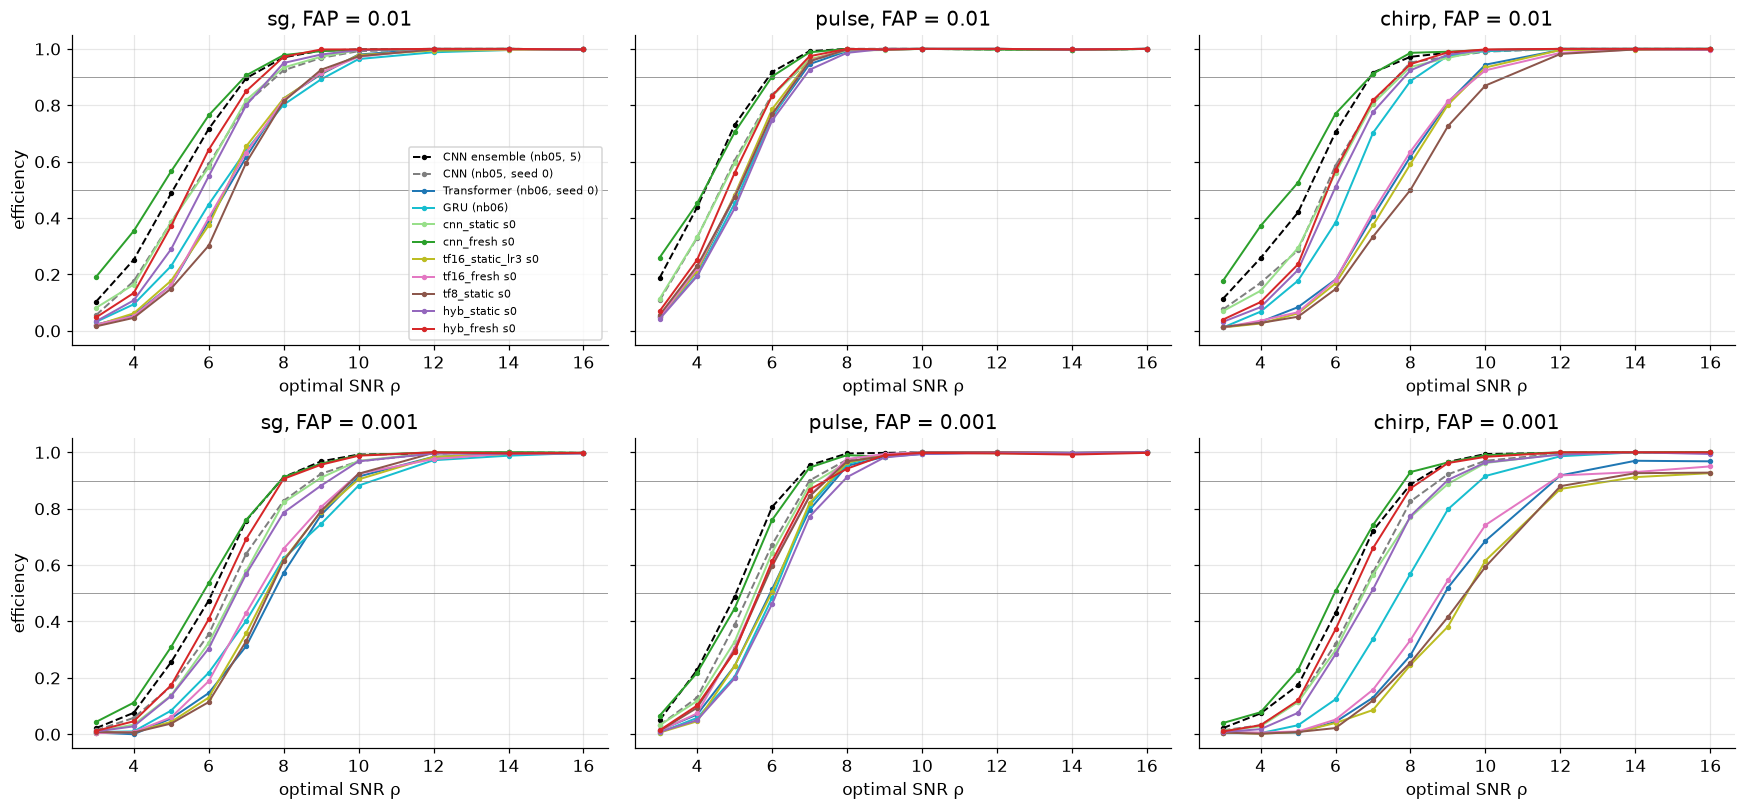

In [7]:
sel = ["CNN ensemble (nb05, 5)", "CNN (nb05, seed 0)", "Transformer (nb06, seed 0)", "GRU (nb06)", "cnn_static s0", "cnn_fresh s0", "tf16_static_lr3 s0", "tf16_fresh s0", "tf8_static s0", "hyb_static s0", "hyb_fresh s0"]
cmap = {"CNN ensemble (nb05, 5)": "k", "CNN (nb05, seed 0)": "#7f7f7f", "Transformer (nb06, seed 0)": g.COLORS["freq"], "GRU (nb06)": "#17becf", "cnn_static s0": "#98df8a", "cnn_fresh s0": g.COLORS["ml"],
        "tf16_static_lr3 s0": "#bcbd22", "tf16_fresh s0": "#e377c2", "tf8_static s0": "#8c564b", "hyb_static s0": g.COLORS["purple"], "hyb_fresh s0": g.COLORS["bayes"]}
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5), sharey=True)
for row, far in zip(ax, (1e-2, 1e-3)):
    for a, kind in zip(row, MORPHS):
        for name in sel: a.plot(SNRS, eff_curve(name, kind, far), color=cmap[name], marker="o", ms=2.5, lw=1.3, ls="--" if name.startswith("CNN") else "-", label=name)
        a.set_title(f"{kind}, FAP = {far:g}"); a.set_xlabel("optimal SNR ρ"); a.axhline(.9, color="grey", lw=.5); a.axhline(.5, color="grey", lw=.5)
    row[0].set_ylabel("efficiency")
ax[0, 0].legend(fontsize=7, loc="lower right"); fig.tight_layout()
g.savefig(fig, "fig07_efficiency"); plt.show()

## 4. Which lever matters?

ρ₅₀ averaged over the three morphologies, for every model, against the reference of notebook 06 (Transformer, 12 epochs, static data). Where two seeds exist the scatter between seeds sets the size of a difference that can be called real.

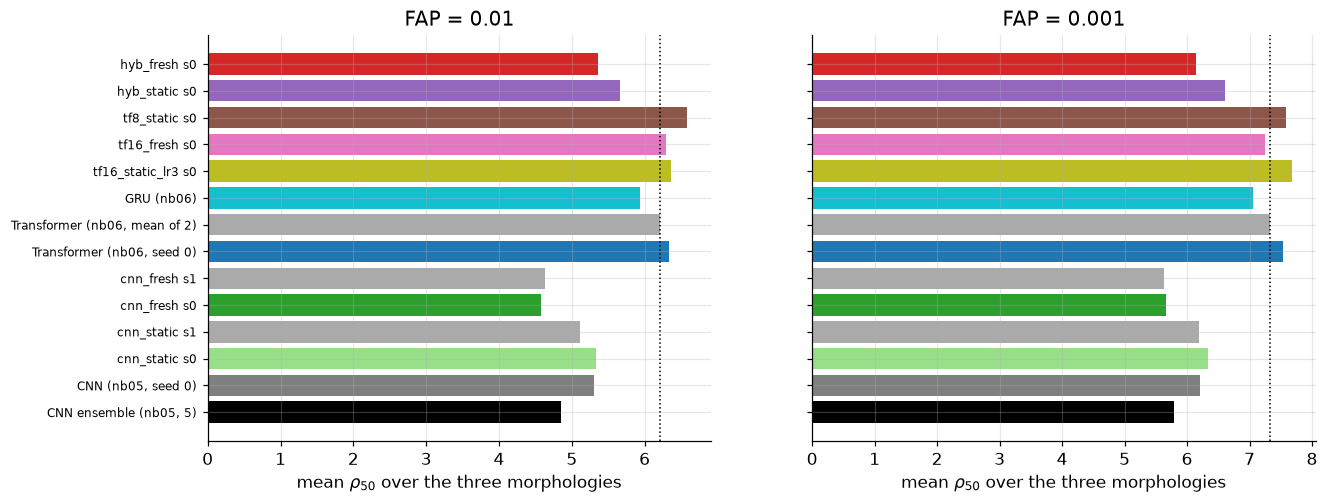

seed-to-seed difference of the mean rho50 (two seeds): {('cnn_static', 0.01): np.float64(0.23), ('cnn_static', 0.001): np.float64(0.14), ('cnn_fresh', 0.01): np.float64(0.06), ('cnn_fresh', 0.001): np.float64(0.02)}


In [8]:
ref = "Transformer (nb06, mean of 2)"
order = ["CNN ensemble (nb05, 5)", "CNN (nb05, seed 0)", "cnn_static s0", "cnn_static s1", "cnn_fresh s0", "cnn_fresh s1", "Transformer (nb06, seed 0)", "Transformer (nb06, mean of 2)", "GRU (nb06)",
         "tf16_static_lr3 s0", "tf16_fresh s0", "tf8_static s0", "hyb_static s0", "hyb_fresh s0"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for a, far in zip(ax, (1e-2, 1e-3)):
    v = [det[(det.model == n) & (det.FAP == far)].rho50.mean() for n in order]
    a.barh(range(len(order)), v, color=[cmap.get(n, "#aaaaaa") for n in order]); a.set_yticks(range(len(order))); a.set_yticklabels(order, fontsize=8)
    a.invert_yaxis(); a.set_xlabel(r"mean $\rho_{50}$ over the three morphologies"); a.set_title(f"FAP = {far:g}")
    a.axvline(det[(det.model == ref) & (det.FAP == far)].rho50.mean(), color="k", ls=":", lw=1)
g.savefig(fig, "fig07_levers"); plt.show()
sc = {}
for base in ("cnn_static", "cnn_fresh"):
    for far in (1e-2, 1e-3):
        v = [det[(det.model == f"{base} s{s}") & (det.FAP == far)].rho50.mean() for s in (0, 1)]; sc[(base, far)] = (v[0], v[1], abs(v[0] - v[1]))
print("seed-to-seed difference of the mean rho50 (two seeds):", {k: round(v[2], 2) for k, v in sc.items()})

In [9]:
summary = dict(diagnosis=diag.to_dict("records"), training=train_tab.to_dict("records"), detection=det.to_dict("records"),
               seed_scatter={f"{k[0]}@{k[1]}": v for k, v in sc.items()},
               lever_mean_rho50={f"{n}@{far}": float(det[(det.model == n) & (det.FAP == far)].rho50.mean()) for n in order for far in (1e-2, 1e-3)})
g.save_json(summary, "07_summary.json"); print("saved")

saved


## 5. Conclusions

Numbers: mean over the three morphologies of ρ₅₀ (optimal SNR at 50 % efficiency), thresholds on the validation noise. Reference: Transformer of notebook 06, ρ₅₀ = 6.20 (FAP 10⁻²) and 7.32 (FAP 10⁻³). **Differences below ≈ 0.3 are not significant**: the seed-to-seed difference of the same configuration is 0.23 and 0.14 (static CNN) and 0.06 and 0.02 (fresh CNN) at FAP 10⁻² and 10⁻³; most variants have a single seed.

1. **The patch Transformer does not recover with any single lever.** Fresh injections (6.29), a three times higher learning rate (6.36), smaller patches (6.59, at four times the cost) and the 25-epoch run of notebook 06 (6.34 against 6.20) all leave it where it was; the validation loss stays at 0.30–0.32. This fits the diagnosis: the model is limited by the embedding/inductive bias, not by data or by optimisation time. Chirps are the worst case (ρ₅₀ ≈ 7.4–8.0 against 5.5–5.8 for the CNN): a 30–80 ms oscillating burst needs frequency-selective filters, which a linear map of 16 raw samples does not provide.
2. **A convolutional stem is the lever that works.** Replacing the patch embedding by the backbone of the CNN followed by two Transformer blocks gives ρ₅₀ = 5.66 (static) and 5.36 (fresh) — a gain of 0.5–0.9 over the patch Transformer, well above the seed scatter — and a validation loss of 0.27/0.25 instead of 0.31. The hybrid is also the only sequence model that is competitive at FAP 10⁻³ (6.14 with fresh injections, against 7.3–7.7).
3. **But the CNN stays ahead with the same data.** Static data: hybrid 5.66 against CNN 5.1–5.3; fresh data: 5.36 against 4.6. The attention on top of a good convolutional front-end does not add detection power on one-second windows with a localised burst; it does not hurt much either.
4. **The CNN of notebooks 05–06 was data-limited, and fresh injections are the best lever of the whole study.** A *single* CNN trained with fresh injections reaches ρ₅₀ = 4.6 at FAP 10⁻² (static: 5.1–5.3) and 5.65 at 10⁻³ (6.2–6.3), better than the 5-member static ensemble of notebook 05 (4.85 and 5.79); ρ₉₀ equals the ensemble's (6.6). Its validation loss drops from 0.17–0.19 to 0.117. This is the reference CNN for any future comparison.
5. **The comparison is not biased in favour of the CNN.** At the nominal FAP of 1 % the observed false-alarm probability on the test chunks is 0.4–0.5 % for the fresh CNN and 0.97–0.99 % for the hybrids: the CNN threshold is the more conservative one, so at equal observed FAP the gap would be larger, not smaller.

**Caveats.** Single seed for the Transformer, GRU and hybrid variants; budget of 12 epochs (the hybrid reaches its best validation epoch at 7 (static) and 11 (fresh), so the longer fresh-data runs might gain a little more); depth, width, number of heads and the masked-patch pre-training were not swept; the unit tested is one second of whitened data with one localised burst — longer windows, or several overlapping signals, are the setting where attention could be expected to matter.

**What it means for the earlier notebooks.** Nothing in notebooks 05–06 is wrong, but their ML numbers were obtained with a data-limited CNN: with fresh injections the ML detectors of notebook 05 would improve by ≈ 0.5–0.7 SNR units (single CNN, FAP 10⁻²). The Transformer-versus-CNN conclusion of notebook 06 survives the stress test and now has a mechanism (the patch embedding), and a remedy that works but does not overtake the CNN (the convolutional stem).

## Output and next step

* `results/07_summary.json`, `figures/fig07_*`; trained models in `cache/models/v07_*` and logits in `cache/stats07.pkl` (not tracked; training by `seq_models.py`, ≈ 1.5 h on four processes).

Possible follow-ups: a second seed for the hybrid and the Transformer variants; fresh injections for the multiclass networks of notebook 06 (the hypothesis-testing results use static data); longer windows.